# 2. Encoder–Decoder Transformer

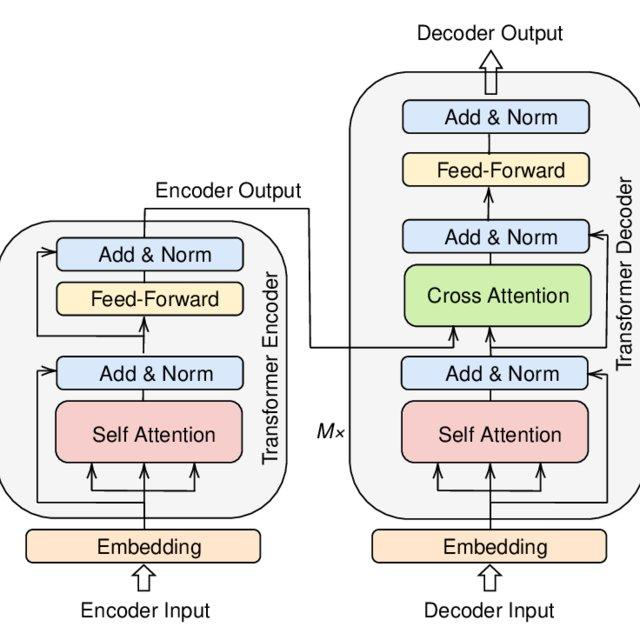

The original Transformer architecture consists of two major components:

```text
Source Sequence
      ↓
   Encoder
      ↓
Encoder Representations
      ↓
   Decoder
      ↓
Target Sequence
```

The **encoder** processes and represents the source sequence, while the **decoder** uses those representations to generate the target sequence.



---

## 2.1 High-Level Architecture

```text
                 SOURCE
                   │
                   ▼
            ┌─────────────┐
            │   ENCODER   │
            └─────────────┘
                   │
                   ▼
        Encoder Representations
                   │
                   │
                   ▼
            ┌─────────────┐
            │   DECODER   │
            └─────────────┘
                   │
                   ▼
                 TARGET
```

More precisely, the decoder receives information from the encoder through **cross-attention**:

```text
                 SOURCE
                   │
                   ▼
              ┌────────┐
              │ ENCODER│
              └────────┘
                   │
                   │ Encoder Output
                   ▼
              ┌────────┐
              │DECODER │◄──── Target Prefix
              └────────┘
                   │
                   ▼
                 TARGET
```

---

## 2.2 Encoder

The encoder receives the **source sequence** and converts it into contextual representations.

```text
Source Tokens
     ↓
Token Embeddings
     ↓
Positional Information
     ↓
Encoder Layers
     ↓
Contextual Representations
```

For example:

```text
"I love machine learning"
          ↓
       Encoder
          ↓
[contextual representation for "I"]
[contextual representation for "love"]
[contextual representation for "machine"]
[contextual representation for "learning"]
```

The encoder's job is to **understand and represent the source sequence**.

It does not directly generate the target sequence.

---

## 2.3 Decoder

The decoder generates the **target sequence**.

For example, in English → French translation:

```text
Source:
"I love machine learning"

Target:
"J'aime l'apprentissage automatique"
```

The decoder generates the target autoregressively:

```text
<START>
   ↓
J'
   ↓
J'aime
   ↓
J'aime l'apprentissage
   ↓
J'aime l'apprentissage automatique
   ↓
<END>
```

At each generation step, the decoder uses:

1. Previously generated target tokens
2. Information from the encoder

---

## 2.4 Cross-Attention

**Cross-attention connects the decoder to the encoder.**

Conceptually:

```text
                 Encoder
                    │
                    │ K, V
                    ▼
              ┌─────────────┐
Decoder Q ──→ │Cross-Attention│
              └─────────────┘
                    │
                    ▼
            Decoder Representation
```

The decoder asks:

> **"Which parts of the source sequence are relevant for generating the next target token?"**

Cross-attention allows the decoder to retrieve that information from the encoder output.

---

## 2.5 Self-Attention vs Cross-Attention

### Self-Attention

Queries, keys, and values come from the **same sequence**:

```text
Sequence
   │
   ├── Q
   ├── K
   └── V
        ↓
  Self-Attention
```

### Cross-Attention

Queries come from the **decoder**, while keys and values come from the **encoder**:

```text
Decoder
   │
   └── Q
        \
         ↓
   Cross-Attention
         ↑
        / \
Encoder
  K     V
```

Mathematically:

$$
\text{CrossAttention}
=
\text{Attention}
\left(
Q_{\text{decoder}},
K_{\text{encoder}},
V_{\text{encoder}}
\right)
$$

Therefore:

$$
Q = \text{Decoder}
$$

$$
K,V = \text{Encoder}
$$

This distinction is **very important for understanding the Transformer decoder**.

---

## 2.6 Example: Machine Translation

Suppose the source is:

```text
"I love machine learning"
```

The encoder creates contextual representations:

```text
"I"       → representation
"love"    → representation
"machine" → representation
"learning"→ representation
```

The decoder begins generating:

```text
<START> → "J'"
```

When generating `"J'"`, `"aime"`, etc., the decoder can use cross-attention to access relevant information from the encoded English sentence.

```text
English Source
      ↓
    Encoder
      ↓
Source Representations
      ↓
Cross-Attention
      ↑
   Decoder
      ↓
French Target
```

---

## 2.7 Complete Encoder–Decoder Flow

```text
SOURCE
  │
  ▼
Token Embeddings
  │
  ▼
Positional Information
  │
  ▼
┌─────────────────────┐
│       ENCODER       │
│                     │
│ Self-Attention      │
│        ↓            │
│ Feed-Forward        │
│        ↓            │
│       ...           │
└─────────────────────┘
  │
  ▼
Encoder Representations
  │
  │
  └─────────────────────────┐
                            │
                            ▼
                    ┌─────────────────┐
TARGET PREFIX ─────►│     DECODER     │
                    │                 │
                    │ Masked          │
                    │ Self-Attention  │
                    │       ↓         │
                    │ Cross-Attention │◄── Encoder Output
                    │       ↓         │
                    │ Feed-Forward    │
                    └─────────────────┘
                            │
                            ▼
                     Output Probabilities
                            │
                            ▼
                       Next Token
```

---

## 2.8 Why Two Components?

The architecture separates two responsibilities:

| Component | Responsibility |
|---|---|
| **Encoder** | Understand and represent the source |
| **Decoder** | Generate the target |
| **Cross-Attention** | Connect target generation with source information |

This makes encoder–decoder Transformers particularly useful for **sequence-to-sequence tasks**.

Examples:

- Machine translation
- Text summarization
- Other sequence transformation tasks

---

## 2.9 Simple Mental Model

A useful analogy:

```text
Encoder = Reader
Decoder = Writer
```

```text
SOURCE
  ↓
┌─────────────┐
│   ENCODER   │
│ "Understand │
│   source"   │
└─────────────┘
       ↓
Source representations
       ↓
┌─────────────┐
│   DECODER   │
│  "Generate  │
│   target"   │
└─────────────┘
       ↓
    TARGET
```

**Cross-attention** is the mechanism that lets the decoder look back at the source representations while generating the target.

---

## 2.10 Interview Points

### What does the encoder do?

> The encoder processes the source sequence and produces contextual representations.

### What does the decoder do?

> The decoder autoregressively generates the target sequence using previously generated tokens and information from the encoder.

### What is cross-attention?

> Cross-attention allows the decoder to attend to the encoder's representations. The decoder provides the queries, while the encoder provides the keys and values.

### What is the difference between self-attention and cross-attention?

**Self-attention:**

$$
Q,K,V \leftarrow \text{same sequence}
$$

**Cross-attention:**

$$
Q \leftarrow \text{decoder}
$$

$$
K,V \leftarrow \text{encoder}
$$

---

## What You Should Remember

1. The **encoder processes the source sequence**.
2. The **decoder generates the target sequence**.
3. The decoder uses **masked self-attention** over previously generated target tokens.
4. The decoder uses **cross-attention** to access encoder representations.
5. In cross-attention:
   - $Q$ comes from the **decoder**
   - $K,V$ come from the **encoder**
6. The encoder–decoder architecture is especially useful for **sequence-to-sequence tasks**.
7. Think of the architecture as:

```text
Source → Encoder → Representations → Decoder → Target
                                      ↑
                               Cross-Attention
```

---